In [2]:
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# Load prepared dataset
data = joblib.load("Dataset/cycle_time_data.joblib")

df = data["df"]
Xraw = data["Xraw"]
yraw = data["yraw"]
FEATURES = data["features"]
TRAIN_END = data["train_end"]

# LSTM configuration
WINDOW = 10
LSTM_UNITS = 50
EPOCHS = 15
BATCH = 32
LR = 0.001
SEED = 0

print("Dataset:", df.shape)
print("Input features:", Xraw.shape)
print("Target:", yraw.shape)
print("Features:", FEATURES)

Dataset: (995, 18)
Input features: (995, 5)
Target: (995,)
Features: ['Processing_Time', 'Energy_Consumption', 'Machine_Availability', 'Upstream_Lag', 'Station_ID']


In [3]:
# Create scalers
sx0 = StandardScaler()
sy0 = StandardScaler()

# Fit using training data only
sx0.fit(Xraw[:TRAIN_END])
sy0.fit(yraw[:TRAIN_END].reshape(-1, 1))

# Transform the entire dataset
X0 = sx0.transform(Xraw)
y0 = sy0.transform(yraw.reshape(-1, 1))

# Check shapes
print("Scaled input:", X0.shape)
print("Scaled target:", y0.shape)

# Verify training scaling
print("Training feature means:", X0[:TRAIN_END].mean(axis=0))
print("Training target mean:", y0[:TRAIN_END].mean())

Scaled input: (995, 5)
Scaled target: (995, 1)
Training feature means: [-4.88498131e-17  1.26565425e-16  6.46149800e-16 -3.99680289e-17
  3.33066907e-17]
Training target mean: -4.884981308350689e-17


In [4]:
# Function to create LSTM sequences
def make_seq(X, y, end_idx_list, window=10):
    Xs = []
    ys = []

    for i in end_idx_list:
        Xs.append(X[i-window:i])
        ys.append(y[i])

    return (
        np.array(Xs, dtype=np.float32),
        np.array(ys, dtype=np.float32)
    )


# Create training sequences
Xtr, ytr = make_seq(
    X0,
    y0,
    range(WINDOW, TRAIN_END),
    window=WINDOW
)

# Check results
print("Training sequences:", Xtr.shape)
print("Training targets:", ytr.shape)

print("First sequence shape:", Xtr[0].shape)
print("First target (scaled):", ytr[0])
print("First target (original):", yraw[WINDOW])

Training sequences: (390, 10, 5)
Training targets: (390, 1)
First sequence shape: (10, 5)
First target (scaled): [-0.16471237]
First target (original): 65.0


In [5]:
# Define LSTM model
class LSTMReg(nn.Module):

    def __init__(self, n_feat, hidden=50):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=n_feat,
            hidden_size=hidden,
            batch_first=True
        )

        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        return self.out(h[:, -1, :])


# Create the LSTM model
model = LSTMReg(
    n_feat=len(FEATURES),
    hidden=LSTM_UNITS
)

print(model)

# Test the model with one training sequence
sample = torch.tensor(Xtr[:1])

output = model(sample)

print("\nInput shape:", sample.shape)
print("Output shape:", output.shape)

LSTMReg(
  (lstm): LSTM(5, 50, batch_first=True)
  (out): Linear(in_features=50, out_features=1, bias=True)
)

Input shape: torch.Size([1, 10, 5])
Output shape: torch.Size([1, 1])


In [6]:
import random

# Set random seed for reproducibility
def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# LSTM training function
def fit(model, X, y, epochs=15, seed=0):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    generator = torch.Generator()
    generator.manual_seed(seed)

    losses = []

    for epoch in range(epochs):

        model.train()
        order = torch.randperm(
            len(X_tensor),
            generator=generator
        )

        epoch_loss = 0

        for start in range(0, len(X_tensor), BATCH):

            idx = order[start:start+BATCH]

            xb = X_tensor[idx]
            yb = y_tensor[idx]

            optimizer.zero_grad()

            predictions = model(xb)

            loss = loss_fn(predictions, yb)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(idx)

        avg_loss = epoch_loss / len(X_tensor)
        losses.append(avg_loss)

        print(
            f"Epoch {epoch+1:02d}/{epochs} "
            f"- MSE Loss: {avg_loss:.4f}"
        )

    return losses


# Initialize a fresh model with a fixed seed
set_seed(SEED)

static = LSTMReg(
    n_feat=len(FEATURES),
    hidden=LSTM_UNITS
)

# Train LSTM
training_losses = fit(
    static,
    Xtr,
    ytr,
    epochs=EPOCHS,
    seed=SEED
)

Epoch 01/15 - MSE Loss: 0.9968
Epoch 02/15 - MSE Loss: 0.9867
Epoch 03/15 - MSE Loss: 0.9844
Epoch 04/15 - MSE Loss: 0.9766
Epoch 05/15 - MSE Loss: 0.9712
Epoch 06/15 - MSE Loss: 0.9650
Epoch 07/15 - MSE Loss: 0.9574
Epoch 08/15 - MSE Loss: 0.9543
Epoch 09/15 - MSE Loss: 0.9434
Epoch 10/15 - MSE Loss: 0.9462
Epoch 11/15 - MSE Loss: 0.9381
Epoch 12/15 - MSE Loss: 0.9329
Epoch 13/15 - MSE Loss: 0.9251
Epoch 14/15 - MSE Loss: 0.9197
Epoch 15/15 - MSE Loss: 0.9070


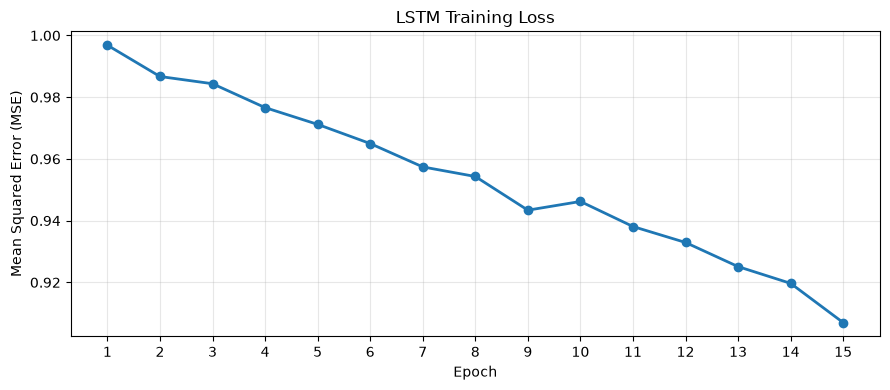

In [7]:
import matplotlib.pyplot as plt

def plot_training_loss(losses):
    plt.figure(figsize=(9, 4))

    plt.plot(
        range(1, len(losses) + 1),
        losses,
        marker="o",
        linewidth=2
    )

    plt.title("LSTM Training Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.xticks(range(1, len(losses) + 1))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_training_loss(training_losses)

In [8]:
# Reusable LSTM prediction function
def predict(model, X):
    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X, dtype=torch.float32
        )
        predictions = model(X_tensor)

    return predictions.numpy()


# First evaluation observation
i = 400

# Use previous 10 observations
X_test = X0[i-WINDOW:i][None]

# Generate prediction
pred_scaled = predict(static, X_test)

# Convert prediction to original processing-time units
pred_original = sy0.inverse_transform(pred_scaled)[0, 0]

print("Predicted processing time:", round(float(pred_original), 2))
print("Actual processing time:", yraw[i])
print("Absolute error:", round(abs(pred_original - yraw[i]), 2))

Predicted processing time: 68.77
Actual processing time: 87.0
Absolute error: 18.23


In [9]:
# Generate predictions for all evaluation observations

results = []

for i in range(TRAIN_END, len(yraw)):

    # Previous 10 observations
    X_test = X0[i-WINDOW:i][None]

    # Predict scaled processing time
    pred_scaled = predict(static, X_test)

    # Convert prediction to original units
    pred_original = sy0.inverse_transform(
        pred_scaled
    )[0, 0]

    results.append({
        "idx": i,
        "phase": df.loc[i, "phase"],
        "actual": yraw[i],
        "predicted": float(pred_original)
    })

# Create results DataFrame
results_df = pd.DataFrame(results)

print("Total predictions:", len(results_df))

display(results_df.head())

Total predictions: 595


,idx,phase,actual,predicted
0,400,stable,87.0,68.765953
1,401,stable,120.0,66.073486
2,402,stable,54.0,67.864563
3,403,stable,31.0,69.677788
4,404,stable,93.0,72.810616


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Function to calculate evaluation metrics
def calculate_metrics(group):

    actual = group["actual"]
    predicted = group["predicted"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return pd.Series({
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })


# Evaluate each operating phase
metrics_df = results_df.groupby(
    "phase", sort=False
).apply(calculate_metrics)

display(metrics_df)

,MAE,RMSE
phase,,
stable,24.28,28.44
drift,61.13,74.04
recovery,30.76,36.26


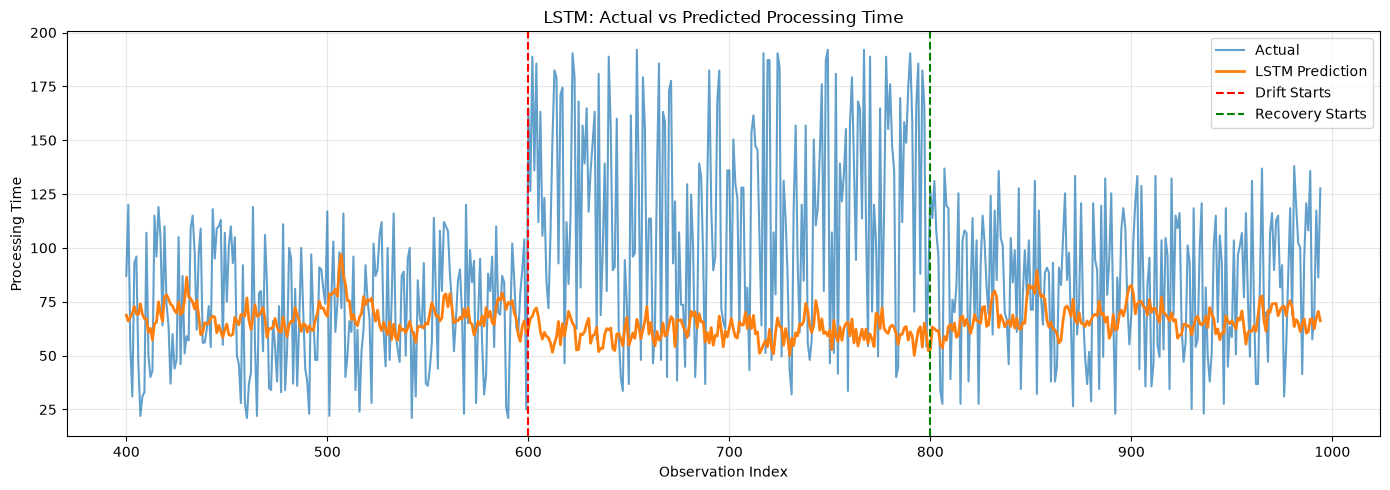

In [11]:
import matplotlib.pyplot as plt

def plot_lstm_predictions(results_df):

    plt.figure(figsize=(14, 5))

    plt.plot(
        results_df["idx"],
        results_df["actual"],
        label="Actual",
        alpha=0.7
    )

    plt.plot(
        results_df["idx"],
        results_df["predicted"],
        label="LSTM Prediction",
        linewidth=2
    )

    # Operating phase boundaries
    plt.axvline(
        x=600, color="red",
        linestyle="--", label="Drift Starts"
    )

    plt.axvline(
        x=800, color="green",
        linestyle="--", label="Recovery Starts"
    )

    plt.title("LSTM: Actual vs Predicted Processing Time")
    plt.xlabel("Observation Index")
    plt.ylabel("Processing Time")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_lstm_predictions(results_df)

In [12]:
from pathlib import Path
import joblib
import torch

# Create output folder
OUTPUT_DIR = Path("Results/LSTM")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save predictions
results_df.to_csv(
    OUTPUT_DIR / "lstm_predictions.csv",
    index=False
)

# Save evaluation metrics
metrics_df.to_csv(
    OUTPUT_DIR / "lstm_metrics.csv"
)

# Save trained model
torch.save(
    static.state_dict(),
    OUTPUT_DIR / "lstm_model.pth"
)

# Save scalers
joblib.dump(
    {"sx": sx0, "sy": sy0},
    OUTPUT_DIR / "lstm_scalers.joblib"
)

print("LSTM results and model saved successfully!")

LSTM results and model saved successfully!


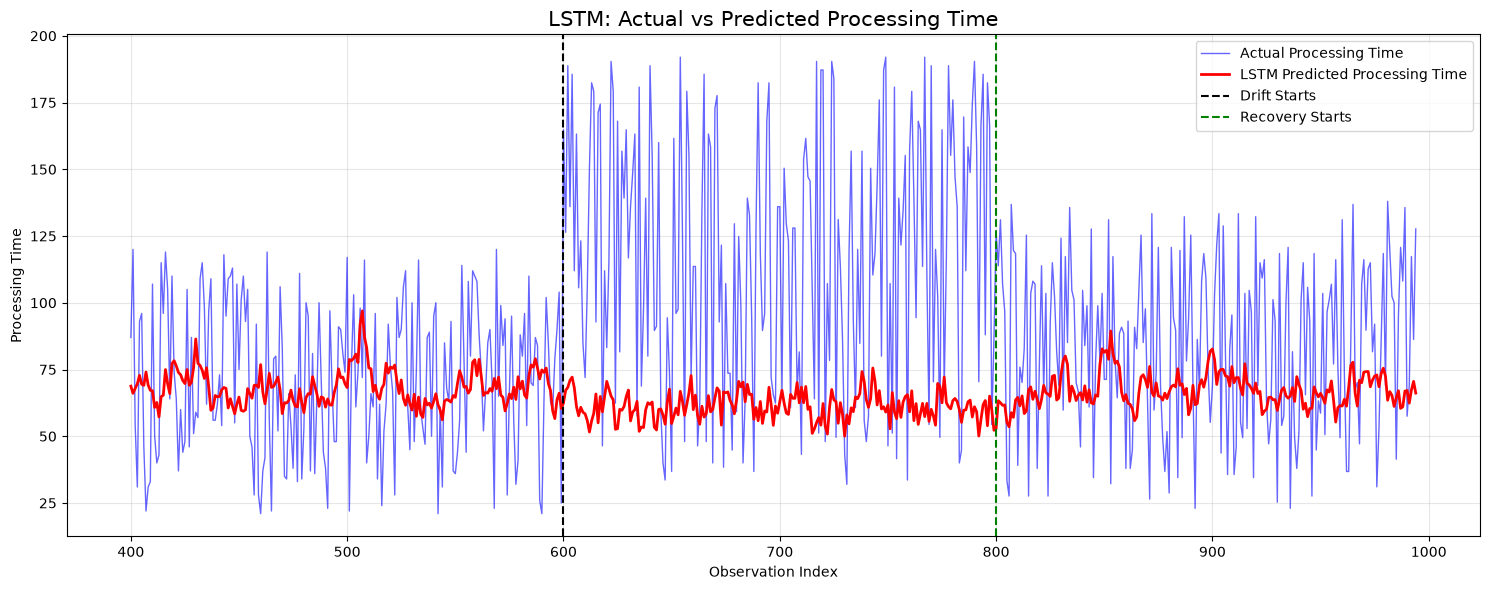

In [14]:
import matplotlib.pyplot as plt

def plot_actual_vs_predicted(results_df):

    plt.figure(figsize=(15, 6))

    # Actual processing time
    plt.plot(
        results_df["idx"],
        results_df["actual"],
        label="Actual Processing Time",
        color="blue",
        alpha=0.6,
        linewidth=1
    )

    # Predicted processing time
    plt.plot(
        results_df["idx"],
        results_df["predicted"],
        label="LSTM Predicted Processing Time",
        color="red",
        linewidth=2
    )

    # Concept drift boundaries
    plt.axvline(
        x=600,
        color="black",
        linestyle="--",
        label="Drift Starts"
    )

    plt.axvline(
        x=800,
        color="green",
        linestyle="--",
        label="Recovery Starts"
    )

    plt.title(
        "LSTM: Actual vs Predicted Processing Time",
        fontsize=15
    )

    plt.xlabel("Observation Index")
    plt.ylabel("Processing Time")

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_actual_vs_predicted(results_df)

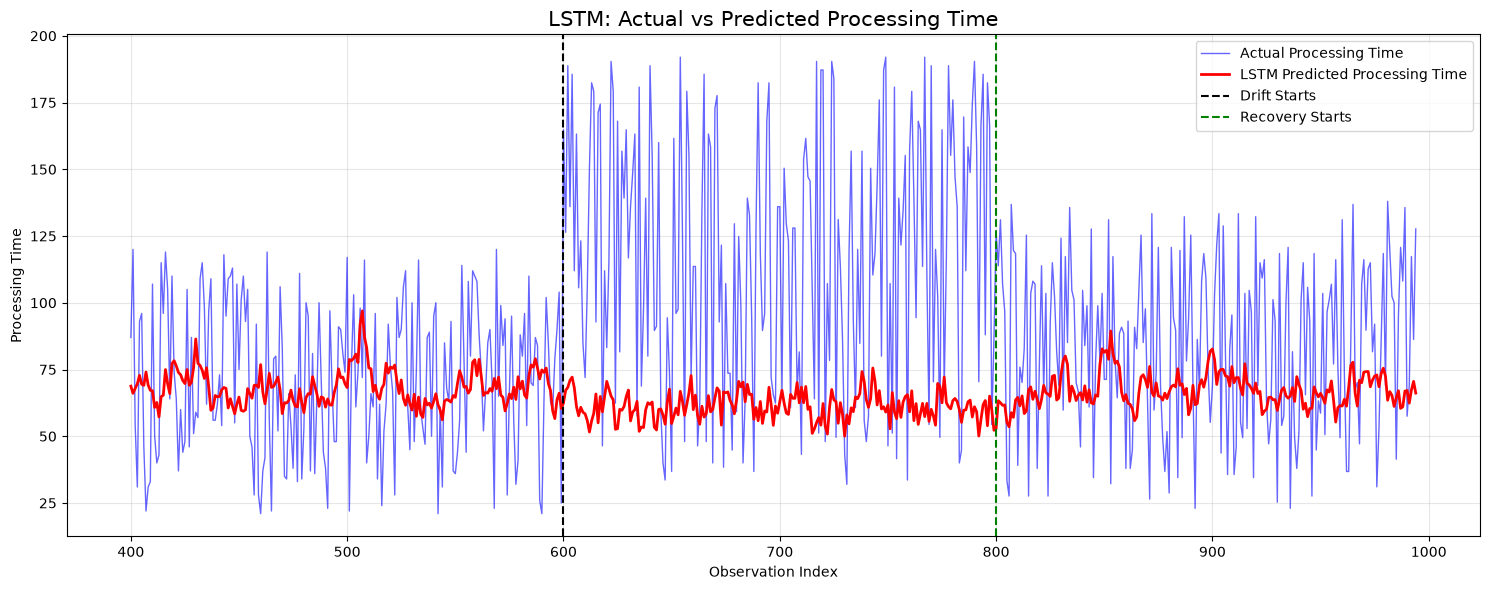

In [15]:
from pathlib import Path

OUTPUT_DIR = Path("Results/LSTM")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Recreate the plot and save it
plot_actual_vs_predicted(results_df)

In [16]:
plt.savefig(
    OUTPUT_DIR / "lstm_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

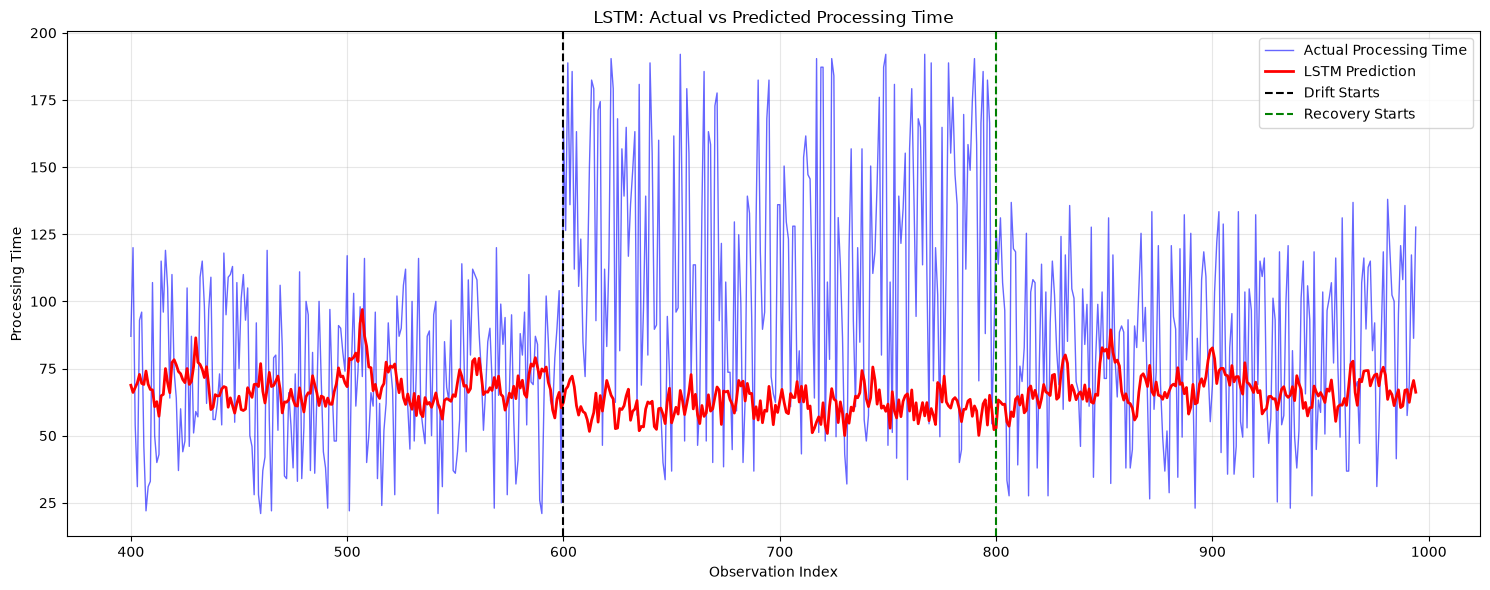

Figure saved successfully!


In [17]:
import matplotlib.pyplot as plt
from pathlib import Path

# Output folder
OUTPUT_DIR = Path("Results/LSTM")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_actual_vs_predicted(results_df):

    fig, ax = plt.subplots(figsize=(15, 6))

    # Actual processing time
    ax.plot(
        results_df["idx"],
        results_df["actual"],
        label="Actual Processing Time",
        color="blue",
        alpha=0.6,
        linewidth=1
    )

    # LSTM predictions
    ax.plot(
        results_df["idx"],
        results_df["predicted"],
        label="LSTM Prediction",
        color="red",
        linewidth=2
    )

    # Concept drift boundaries
    ax.axvline(
        x=600,
        color="black",
        linestyle="--",
        label="Drift Starts"
    )

    ax.axvline(
        x=800,
        color="green",
        linestyle="--",
        label="Recovery Starts"
    )

    ax.set_title("LSTM: Actual vs Predicted Processing Time")
    ax.set_xlabel("Observation Index")
    ax.set_ylabel("Processing Time")

    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    # IMPORTANT: Save BEFORE displaying
    fig.savefig(
        OUTPUT_DIR / "lstm_actual_vs_predicted.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Figure saved successfully!")


# Generate and save the plot
plot_actual_vs_predicted(results_df)